# Operando Pipeline Runner

Fill in the paths below, then run all cells.

This notebook loads `operando data.py` and `operando plots.py` relative to the `toolbox/operando` folder so it works regardless of where `toolbox` lives.

In [1]:
# Imports
import os
import importlib.util

# Resolve module paths relative to this notebook location
# Assumes this notebook lives in toolbox/operando
notebook_dir = os.path.abspath(os.getcwd())
data_module_path = os.path.join(notebook_dir, "operando data.py")
plots_module_path = os.path.join(notebook_dir, "operando plots.py")

# Load operando data module
data_spec = importlib.util.spec_from_file_location("operando_data", data_module_path)
operando_data = importlib.util.module_from_spec(data_spec)
data_spec.loader.exec_module(operando_data)

# Load operando plots module
plots_spec = importlib.util.spec_from_file_location("operando_plots", plots_module_path)
operando_plots = importlib.util.module_from_spec(plots_spec)
plots_spec.loader.exec_module(operando_plots)

run_operando_pipeline = operando_data.run_operando_pipeline


In [2]:
# === Base directory ===
# Set this to the root folder that contains your data_raw folder
base_dir = r"/data01/Leon_BOA_December2025"

# === Paths under base_dir ===
exp_dir = os.path.join(base_dir, "LiMetal/exp1301_LiMetal_final")
beamhistory_path = os.path.join(base_dir, "LiMetal/Leon_BOA_Dec2025_exp1301_LiMetal_final_1s.csv")
reference_dir = os.path.join(base_dir, "Ref/exp004_Ref1um_NewCell_40x20NA_wmetal")
reference_beamhistory_path = os.path.join(base_dir, "Ref/Leon_BOA_Dec2025_Ref.csv")

echem_folder = os.path.join(base_dir, "EChem_Dec 02-09 2025 (BOA)/6Lithium Metal")
video_output_path = os.path.join(base_dir, "LiMetal/exp1301_LiMetal_final.mp4")

# Optional
output_dir = None  # auto-name with experiment folder
exposure_seconds = 2
uncorrected_output_folder_name = None  # auto-name with experiment folder


In [3]:
# Run pipeline
result = run_operando_pipeline(
    exp_dir=exp_dir,
    beamhistory_path=beamhistory_path,
    output_dir=output_dir,
    exposure_seconds=exposure_seconds,
    reference_dir=reference_dir,
    reference_beamhistory_path=reference_beamhistory_path,
    uncorrected_output_folder_name=uncorrected_output_folder_name,
)

result


{'corrected_dir': '/data01/Leon_BOA_December2025/LiMetal/obint_corrected_exp1301_LiMetal_final',
 'uncorrected_dir': '/data01/Leon_BOA_December2025/LiMetal/uncorrected_exp1301_LiMetal_final',
 'reference_beam_integral_per_minute': 83389.54284559663}

## Background Subtraction (Post-ImageJ)
 This section subtracts a background TIFF from the corrected images and writes intermediate and final outputs.


In [5]:
from pathlib import Path
import numpy as np
import tifffile

# === Fill these in ===
# Path to background TIFF to subtract
background_path = os.path.join(base_dir, "LiMetal/spotfix_corrected_tiffs_exp1301_LiMetal_final.tif")

# Input corrected folder (from pipeline)
corrected_dir = Path(result["corrected_dir"])

# Final output folder (sibling to corrected_dir)
exp_name = corrected_dir.name.replace("obint_corrected_", "")
final_dir = corrected_dir.parent / ("final_" + exp_name)
final_dir.mkdir(parents=True, exist_ok=True)

# Load background image
bg = tifffile.imread(background_path).astype(np.float32)

def read_custom_tags(path):
    try:
        with tifffile.TiffFile(path) as tif:
            tags = tif.pages[0].tags
            out = {}
            for code in (65000, 65001, 65002):
                if code in tags:
                    out[code] = tags[code].value
            return out
    except Exception:
        return {}

for p in sorted(corrected_dir.iterdir()):
    if not p.is_file():
        continue
    try:
        img = tifffile.imread(str(p)).astype(np.float32)
    except Exception:
        continue

    if img.shape != bg.shape:
        raise ValueError(f"Background shape {bg.shape} does not match image {p.name} shape {img.shape}")

    bgsub = img - bg

    # Optional: clip negatives
    # bgsub = np.maximum(bgsub, 0)

    tags = read_custom_tags(str(p))
    extratags = []
    if 65001 in tags:
        extratags.append((65001, "d", 1, float(tags[65001]), False))
    if 65000 in tags:
        extratags.append((65000, "s", 0, tags[65000], False))
    if 65002 in tags:
        extratags.append((65002, "s", 0, tags[65002], False))

    final_path = final_dir / p.name
    tifffile.imwrite(str(final_path), bgsub.astype(np.float32), extratags=extratags)

print("Wrote:", final_dir)

Wrote: /data01/Leon_BOA_December2025/LiMetal/final_exp1301_LiMetal_final


### The images should have been OB-corrected with the reference image. Before plotting, you may need to manually filter bright spots from TPX hot pixels.

# Plotting and Video

This section loads corrected images, extracts `MeanTPXModifiedTime` from TIFF tags, loads electrochemical data, then creates:
- A potential + image video
- A potential + thickness plot

In [6]:
# Plot/video settings
conv_thickness = 1.0
time_column = "time/s"
fps = 10
dt_seconds = 120
cmap = "inferno"
vmin = None
vmax = None
dpi = 150
merge_minutes = 1
merge_method = "mean"
roi = dict(r0=160, x0=224, y0=219)
potential_ylim=(-0.4, 0.6)

In [7]:
import tifffile
from datetime import datetime

def load_corrected_images_with_time(corrected_dir, tag_id=65002, r0=None, x0=None, y0=None):
    records = []
    for fname in sorted(os.listdir(corrected_dir)):
        path = os.path.join(corrected_dir, fname)
        if not os.path.isfile(path):
            continue
        # Try to open as TIFF (works even if no extension)
        try:
            with tifffile.TiffFile(path) as tif:
                img = tif.asarray()
                if r0 is not None and x0 is not None and y0 is not None:
                    y_start = max(0, y0 - r0)
                    y_end = min(img.shape[0], y0 + r0)
                    x_start = max(0, x0 - r0)
                    x_end = min(img.shape[1], x0 + r0)
                    img = img[y_start:y_end, x_start:x_end]
                tags = tif.pages[0].tags
                if tag_id not in tags:
                    continue
                dt_str = tags[tag_id].value
        except Exception:
            continue

        # Parse datetime
        try:
            dt = datetime.strptime(dt_str, "%Y-%m-%d %H:%M:%S")
        except Exception:
            continue

        records.append((dt, img, path))

    records.sort(key=lambda x: x[0])
    img_datetimes = [r[0] for r in records]
    img_series = [r[1] for r in records]
    paths = [r[2] for r in records]
    return img_datetimes, img_series, paths


In [8]:
# Load final images (MeanTPXModifiedTime)
img_datetimes, img_series, img_paths = load_corrected_images_with_time(
    final_dir,
    tag_id=65002,
    r0=roi["r0"],
    x0=roi["x0"],
    y0=roi["y0"],
)


# Load electrochemical data
echem_datetimes, potential_series, echem_thickness_series = operando_plots.load_echem_data(
    echem_folder,
    conv_thickness=conv_thickness,
    time_column=time_column,
)

# Optionally merge images in time
img_datetimes, img_series = operando_plots.merge_images_by_time(
    img_datetimes, img_series, merge_minutes=merge_minutes, method=merge_method
)


In [9]:
print(final_dir)

/data01/Leon_BOA_December2025/LiMetal/final_exp1301_LiMetal_final


In [10]:
# Make potential + image video
operando_plots.make_potential_image_video_uniform_time(
    echem_datetimes=echem_datetimes,
    potential_series=potential_series,
    img_datetimes=img_datetimes,
    img_series=img_series,
    output_path=video_output_path,
    fps=fps,
    dt_seconds=dt_seconds,
    dpi=dpi,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    potential_ylim=potential_ylim
)


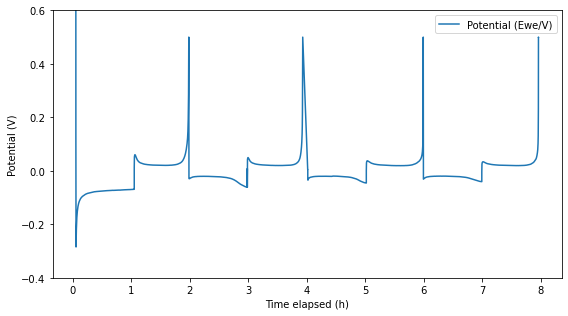

In [11]:
# Make potential + thickness plot (image-derived thickness)
avg_thickness_series = operando_plots.circular_average_thickness_series(
    img_series, **roi
)

operando_plots.plot_potential_and_thickness(
    echem_datetime_series=echem_datetimes,
    potential_series=potential_series,
    echem_thickness_series=echem_thickness_series,
    img_datetime_series=img_datetimes,
    avg_thickness_series=avg_thickness_series,
    potential_ylim=potential_ylim
)
